In [1]:
!pip install -q gradio tqdm

import gradio as gr
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import os
import zipfile
import numpy as np
from google.colab import files
from tqdm.notebook import tqdm

# Set device to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"System ready. Using device: {device}")

System ready. Using device: cuda


In [3]:
# uploading file
print("Please upload your CIFAKE zip file (e.g., archive.zip):")
uploaded = files.upload()
# file extraction

if len(uploaded) > 0:
    zip_filename = next(iter(uploaded))
    print(f"Extracting {zip_filename}...")

    # Creating directory
    extract_path = "cifake"
    if not os.path.exists(extract_path):
        os.makedirs(extract_path)

    # Unziping the file
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully.")
else:
    print("No file uploaded. Please re-run this cell.")

Please upload your CIFAKE zip file (e.g., archive.zip):


Saving archive (2) (1).zip to archive (2) (1).zip
Extracting archive (2) (1).zip...
Dataset extracted successfully.


In [ ]:

train_dir = os.path.join("cifake", "train")
test_dir = os.path.join("cifake", "test")
# preprocessing the data
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Loading Datasets
if os.path.exists(train_dir) and os.path.exists(test_dir):
    train_dataset = datasets.ImageFolder(train_dir, transform=transform_pipeline)
    test_dataset = datasets.ImageFolder(test_dir, transform=transform_pipeline)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    class_names = train_dataset.classes
    print(f"Data Loaded. Training on {len(train_dataset)} images.")
else:
    print("Error: Dataset directories not found.")

Data Loaded. Training on 100000 images.


In [ ]:
# DINOv2 architecture
class DINOv2Classifier(nn.Module):
    def __init__(self, num_classes=2):
        super(DINOv2Classifier, self).__init__()
        self.backbone = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
        for param in self.backbone.parameters():
            param.requires_grad = False
        self.head = nn.Linear(384, num_classes)

    def forward(self, x):
        features = self.backbone(x)
        output = self.head(features)
        return output

# initialization of model
print("Initializing DINOv2...")
dino_model = DINOv2Classifier(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(dino_model.head.parameters(), lr=0.00005)
# training the model
EPOCHS = 3
print(f"Starting DINOv2 Training for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    dino_model.train()
    running_loss = 0.0
    correct = 0
    total = 0


    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = dino_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()


        loop.set_postfix(loss=loss.item(), acc=100 * correct / total)


    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    print(f"Epoch {epoch+1} complete | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("DINOv2 Training Complete.")

Initializing DINOv2...
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 321MB/s]


Starting DINOv2 Training for 3 epochs...


Epoch 1/3:   0%|          | 0/3125 [00:00<?, ?it/s]

Epoch 1 complete | Loss: 0.3321 | Accuracy: 85.47%


Epoch 2/3:   0%|          | 0/3125 [00:00<?, ?it/s]

Epoch 2 complete | Loss: 0.2002 | Accuracy: 92.14%


Epoch 3/3:   0%|          | 0/3125 [00:00<?, ?it/s]

Epoch 3 complete | Loss: 0.1804 | Accuracy: 92.93%
DINOv2 Training Complete.


In [ ]:
# ResNet18 Architecture
def get_resnet18_model():
    model = models.resnet18(weights="IMAGENET1K_V1")
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 2)
    return model

# initialization of the model
print("Initializing ResNet18...")
resnet_model = get_resnet18_model().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.parameters(), lr=0.0001)

# Training the model
EPOCHS = 5
print(f"Starting ResNet18 Training for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    resnet_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        loop.set_postfix(loss=loss.item(), acc=100 * correct / total)

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    print(f"Epoch {epoch+1} complete | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("ResNet18 Training Complete.")

Initializing ResNet18...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


Starting ResNet18 Training for 5 epochs...


Epoch 1/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Epoch 1 complete | Loss: 0.1292 | Accuracy: 95.09%


Epoch 2/5:   0%|          | 0/3125 [00:00<?, ?it/s]

... (3 outputs left out)

Epoch 4/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Epoch 4 complete | Loss: 0.0384 | Accuracy: 98.60%


Epoch 5/5:   0%|          | 0/3125 [00:00<?, ?it/s]

Epoch 5 complete | Loss: 0.0294 | Accuracy: 98.92%
ResNet18 Training Complete.


Evaluating DINOv2 on Test Data...


Testing DINOv2:   0%|          | 0/625 [00:00<?, ?it/s]

FINAL RESULT: DINOv2 Accuracy: 93.40%
FINAL RESULT: DINOv2 F1 Score: 0.9340


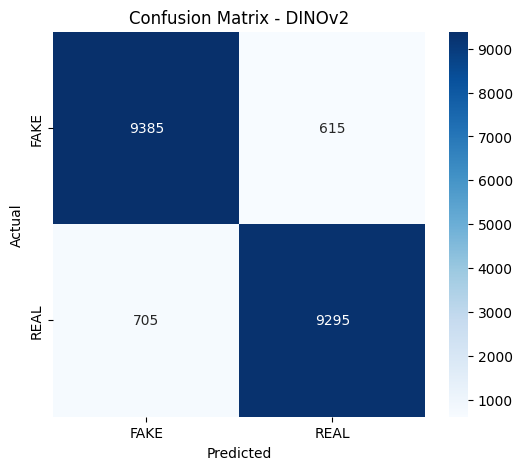

Evaluating ResNet18 on Test Data...


Testing ResNet18:   0%|          | 0/625 [00:00<?, ?it/s]

FINAL RESULT: ResNet18 Accuracy: 98.25%
FINAL RESULT: ResNet18 F1 Score: 0.9825


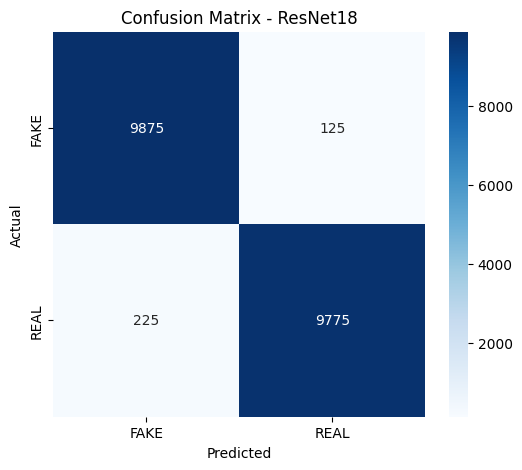

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, confusion_matrix

def evaluate_model(model, loader, name):
    model.eval()
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    print(f"Evaluating {name} on Test Data...")
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=f"Testing {name}"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()


            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())

    # Calculate Accuracy
    accuracy = 100 * correct / total
    print(f"FINAL RESULT: {name} Accuracy: {accuracy:.2f}%")

    # Calculate F1 Score
    f1 = f1_score(all_labels, all_predictions, average='weighted')
    print(f"FINAL RESULT: {name} F1 Score: {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_predictions)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

    return accuracy

# Evaluating both the models
dino_acc = evaluate_model(dino_model, test_loader, "DINOv2")
resnet_acc = evaluate_model(resnet_model, test_loader, "ResNet18")

In [ ]:
def predict_image(image, model_choice):
    if image is None:
        return None

    # Preparing image
    image_tensor = transform_pipeline(image).unsqueeze(0).to(device)

    # Switching models
    if model_choice == "DINOv2 (Transformer)":
        selected_model = dino_model
    else:
        selected_model = resnet_model

    selected_model.eval()

    # Predicting the image
    with torch.no_grad():
        logits = selected_model(image_tensor)
        probs = torch.nn.functional.softmax(logits[0], dim=0)

    return {
        "FAKE": float(probs[0]),
        "REAL": float(probs[1])
    }

# Building Interface
interface = gr.Interface(
    fn=predict_image,
    inputs=[
        gr.Image(type="pil", label="Upload Image"),
        gr.Dropdown(
            choices=["DINOv2 (Transformer)", "ResNet18 (CNN)"],
            value="ResNet18 (CNN)",
            label="Select Model"
        )
    ],
    outputs=gr.Label(num_top_classes=2, label="Confidence Score"),
    title="Image Detection System",
    description="Live comparison of ResNet18 (CNN) vs DINOv2 (Transformer) trained on CIFAKE.",
    theme="soft"
)

interface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c3738326fdd54c0fb1.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
